# 02 · Preparación de los datos (CRISP-DM fase 3)

Prerrequisito del Sprint 2. Pasos: (1) fuente única `Faces`, (2) agrupar casi duplicados, (3) reparto de identidades registradas/impostoras,
(4) división 70/15/15 de las registradas por grupos, (5) comprobaciones, (6) preprocesado (tamaño y normalización) y caché.

**Protocolo confirmado (2026-10-23):** 24 identidades registradas y 7 impostoras (3 para validación, 4 para prueba), separadas por identidad,
semilla 42. Marmik va forzado a registradas y Kashyap a impostoras de prueba.

**Sorteo estratificado por género (aproximado):** el dataset no trae género, así que se asignó una etiqueta M/F **solo a partir del nombre
de pila** (no de los rostros), confirmada por el usuario (`C.GENDER_BY_NAME`). Es una aproximación y se usa **únicamente para estratificar**.
Cuotas: validación 2M + 1F; prueba 2M (Kashyap + 1 sorteado) + 2F. Así quedan 12M + 12F registradas.

*Sorteo descartado:* el primer sorteo, sin estratificar, puso en validación solo mujeres (Claire Holt, Ellen Degeneres, Jessica Alba).
Se descartó **antes de entrenar o evaluar ningún modelo** (no existían métricas), solo por el desequilibrio de género.

No se detectan rostros: `Faces` ya viene recortado a 160×160.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from PIL import Image
from src import config as C, data as D
C.FIGS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True})
SERIES = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}  # slots categoricos 1-3
print("Semilla:", C.SEED)
C.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

Semilla: 42


## 1. Grupos de casi duplicados

In [2]:
df = D.load_index()
df, pairs, S = D.group_near_duplicates(df)
gs = df.groupby("group_id").size()
print(f"Imágenes: {len(df)} | grupos: {gs.size} | grupos con >1 imagen: {(gs>1).sum()} | imágenes en esos grupos: {gs[gs>1].sum()} | grupo más grande: {gs.max()}")
pairs.to_csv(C.DOCS / "02_pares_casi_duplicados.csv", index=False)
pairs.sort_values("corr", ascending=False).head(10)

Imágenes: 2562 | grupos: 2425 | grupos con >1 imagen: 93 | imágenes en esos grupos: 230 | grupo más grande: 12


,file_a,file_b,person,corr,md5_identico
81,Hugh Jackman_82.jpg,Hugh Jackman_83.jpg,Hugh Jackman,1.000001,True
48,Courtney Cox_23.jpg,Courtney Cox_45.jpg,Courtney Cox,1.000000,True
67,Henry Cavill_25.jpg,Henry Cavill_5.jpg,Henry Cavill,1.000000,True
116,Natalie Portman_92.jpg,Natalie Portman_93.jpg,Natalie Portman,1.000000,True
41,Courtney Cox_10.jpg,Courtney Cox_9.jpg,Courtney Cox,0.999999,True
115,Natalie Portman_71.jpg,Natalie Portman_73.jpg,Natalie Portman,0.999937,False
103,Kashyap_13.jpg,Kashyap_14.jpg,Kashyap,0.996915,False
23,Brad Pitt_105.jpg,Brad Pitt_110.jpg,Brad Pitt,0.992524,False
31,Camila Cabello_23.jpg,Camila Cabello_54.jpg,Camila Cabello,0.990830,False
143,Vijay Deverakonda_78.jpg,Vijay Deverakonda_83.jpg,Vijay Deverakonda,0.989087,False


## 2. Reparto de identidades

In [3]:
df = D.make_splits(df)
df["genero_aprox"] = df.person.map(C.GENDER_BY_NAME)
roles = df.groupby("role").person.unique().map(sorted)
for r, ps in roles.items(): print(f"{r} ({len(ps)}): {', '.join(ps)}")
pd.crosstab(df.drop_duplicates("person").role, df.drop_duplicates("person").genero_aprox, margins=True)

impostora_test (4): Courtney Cox, Hugh Jackman, Kashyap, Natalie Portman
impostora_val (3): Andy Samberg, Elizabeth Olsen, Henry Cavill
registrada (24): Akshay Kumar, Alexandra Daddario, Alia Bhatt, Amitabh Bachchan, Anushka Sharma, Billie Eilish, Brad Pitt, Camila Cabello, Charlize Theron, Claire Holt, Dwayne Johnson, Ellen Degeneres, Hrithik Roshan, Jessica Alba, Lisa Kudrow, Margot Robbie, Marmik, Priyanka Chopra, Robert Downey Jr, Roger Federer, Tom Cruise, Vijay Deverakonda, Virat Kohli, Zac Efron


genero_aprox,F,M,All
role,,,
impostora_test,2,2,4
impostora_val,1,2,3
registrada,12,12,24
All,15,16,31


## 3. Conteos por conjunto

In [4]:
t = pd.crosstab(df.person, df.split).reindex(columns=["train", "val", "test"]).fillna(0).astype(int)
t["total"] = t.sum(1); t["rol"] = df.groupby("person").role.first(); t["genero_aprox"] = t.index.map(C.GENDER_BY_NAME)
t = t.sort_values(["rol", "total"], ascending=[False, False]); t

split,train,val,test,total,rol,genero_aprox
person,,,,,,
Brad Pitt,84,18,18,120,registrada,M
Vijay Deverakonda,80,18,17,115,registrada,M
Robert Downey Jr,79,17,17,113,registrada,M
Jessica Alba,75,17,16,108,registrada,F
Priyanka Chopra,70,16,16,102,registrada,F
Hrithik Roshan,70,16,15,101,registrada,M
Billie Eilish,68,15,15,98,registrada,F
Claire Holt,66,15,15,96,registrada,F
Alexandra Daddario,63,15,14,92,registrada,F


In [5]:
res = df.groupby(["role", "split"]).agg(imagenes=("filename", "size"), personas=("person", "nunique")).reset_index()
reg = df[df.role == "registrada"].split.value_counts(normalize=True).reindex(["train","val","test"])
print("Proporciones en registradas:", (reg*100).round(1).to_dict())
res.to_csv(C.DOCS / "02_conteos_por_conjunto.csv", index=False); res

Proporciones en registradas: {'train': 69.3, 'val': 15.5, 'test': 15.2}


,role,split,imagenes,personas
0,impostora_test,test,327,4
1,impostora_val,val,269,3
2,registrada,test,299,24
3,registrada,train,1362,24
4,registrada,val,305,24


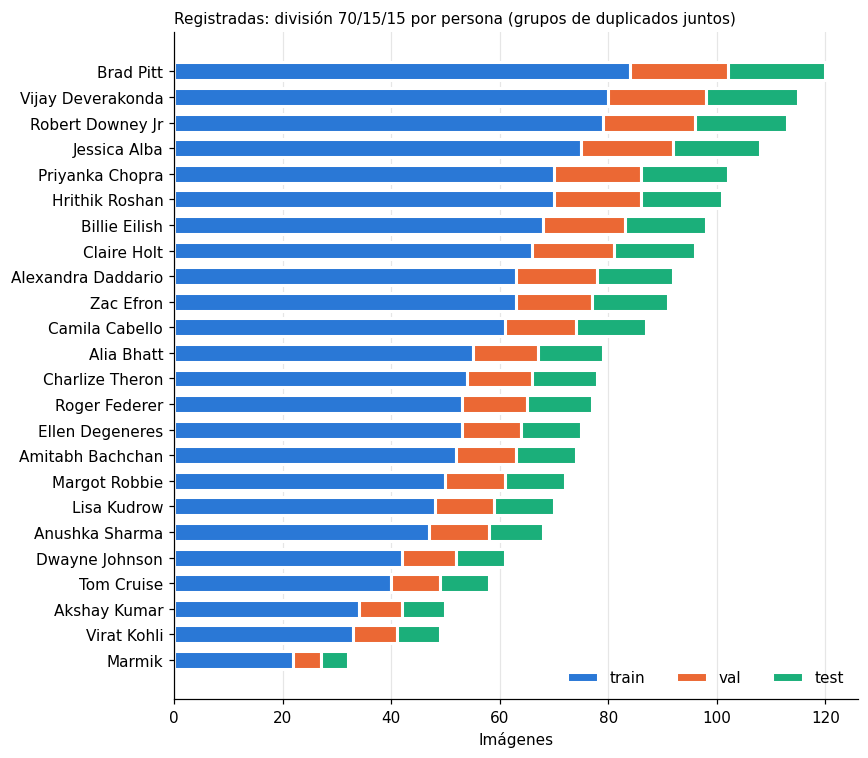

In [6]:
tr = t[t.rol == "registrada"].sort_values("total")
fig, ax = plt.subplots(figsize=(8, 7))
left = np.zeros(len(tr))
for s in ["train", "val", "test"]:
    ax.barh(tr.index, tr[s], left=left, color=SERIES[s], label=s, height=0.7, edgecolor="white", linewidth=2)
    left += tr[s].values
ax.legend(frameon=False, ncol=3, loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Imágenes"); ax.set_title("Registradas: división 70/15/15 por persona (grupos de duplicados juntos)", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(C.FIGS / "02_division_registradas.png"); plt.show()

## 4. Comprobaciones de integridad

In [7]:
assert D.check_splits(df)
assert df[df.role=="registrada"].person.nunique() == 24 and df[df.role!="registrada"].person.nunique() == 7
assert df.loc[df.person=="Marmik","role"].iloc[0] == "registrada" and df.loc[df.person=="Kashyap","role"].iloc[0] == "impostora_test"
assert (t[t.rol=="registrada"][["train","val","test"]] > 0).all().all(), "alguna registrada sin fotos en algún conjunto"
print("OK: sin imágenes ni grupos de casi duplicados repartidos entre conjuntos; impostores nunca en train;")
print("    identidades impostoras de val y de test disjuntas; todas las registradas tienen train/val/test.")
# Nota extra: pares muy similares (>=0.88) entre conjuntos distintos, para documentar el riesgo residual
iu = np.triu_indices(len(df), 1); c = S[iu]
sp = df.split.values; pe = df.person.values
m = (c >= 0.85) & (pe[iu[0]] == pe[iu[1]]) & (sp[iu[0]] != sp[iu[1]])
print(f"Pares de la misma persona con corr en [0.85, {C.DUP_CORR_THRESHOLD}) en conjuntos distintos: {m.sum()} (por debajo del umbral; fotos parecidas pero no casi idénticas)")

OK: sin imágenes ni grupos de casi duplicados repartidos entre conjuntos; impostores nunca en train;
    identidades impostoras de val y de test disjuntas; todas las registradas tienen train/val/test.


Pares de la misma persona con corr en [0.85, 0.9) en conjuntos distintos: 178 (por debajo del umbral; fotos parecidas pero no casi idénticas)


## 5. Preprocesado

- **Tamaño 160×160**: las caras ya vienen así (no se reescala ni se pierde detalle); es la entrada nativa de FaceNet. Si otro modelo
  necesita 112×112 (p. ej. ArcFace) se reescalará dentro de su propio preprocesado.
- **Color**: RGB (OpenCV lee BGR; se convierte).
- **Normalización**: `(x − 127.5) / 128` → aprox. [−1, 1], la de FaceNet (`D.standardize`). Se aplica al cargar, no se guarda.
- **Aumento de datos** (solo para entrenar la CNN propia, solo sobre train): se definirá en la fase de modelado.
- Se guarda una caché `data/processed/faces160.npz` (uint8) y la tabla `data/processed/splits.csv`, ambas fuera de git.

In [8]:
X = D.load_images(df.path.tolist())
print("Array:", X.shape, X.dtype, "| tras normalizar:", D.standardize(X[:4]).shape, "rango",
      round(float(D.standardize(X[:200]).min()),3), round(float(D.standardize(X[:200]).max()),3))
cols = ["filename", "person", "genero_aprox", "group_id", "role", "split"]
df[cols].to_csv(C.DATA_PROCESSED / "splits.csv", index=False)
df[cols].to_csv(C.DOCS / "02_splits.csv", index=False)  # copia para el informe (solo nombres, sin imágenes)
np.savez_compressed(C.DATA_PROCESSED / "faces160.npz", X=X, filename=df.filename.values)
print("Guardado:", C.DATA_PROCESSED / "splits.csv", "y faces160.npz")

Array: (2562, 160, 160, 3) uint8 | tras normalizar: (4, 3, 160, 160) rango -0.996 0.996


Guardado: D:\IA\FaceID\data\processed\splits.csv y faces160.npz


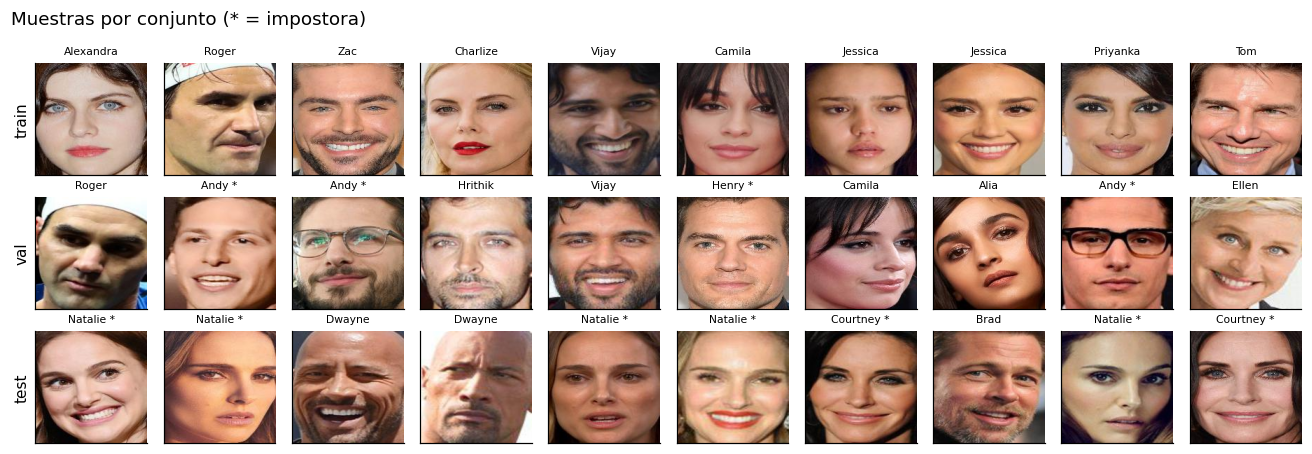

In [9]:
fig, axes = plt.subplots(3, 10, figsize=(12, 4.2))
for row, s in zip(axes, ["train", "val", "test"]):
    sub = df[df.split == s].sample(10, random_state=C.SEED)
    for a, (_, r) in zip(row, sub.iterrows()):
        a.imshow(D.read_rgb(r.path)); a.set_xticks([]); a.set_yticks([]); a.grid(False)
        a.set_title(r.person.split()[0] + (" *" if r.role != "registrada" else ""), fontsize=7)
    row[0].set_ylabel(s, fontsize=10)
plt.suptitle("Muestras por conjunto (* = impostora)", x=0.01, ha="left"); plt.tight_layout()
plt.savefig(C.FIGS / "02_muestras_por_conjunto.png"); plt.show()